<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Which pages deserve a bounded index-status review?

A page with a high desktop click-through rate can still have a low combined rate when most impressions are mobile. We combine device rows using their actual denominators, then inspect a small, explicit shortlist.

**All traffic and index statuses here are invented.** A loopback API serves the bundled synthetic fixture through the unchanged real worker. Nothing is fetched from a Google account. The data covers 2026-09-01 through 2026-09-07, inclusive Pacific Time dates; inspection statuses are a separate synthetic snapshot. No change in CTR is attributed to an index status.

## One review threshold

`MIN_IMPRESSIONS` is the minimum returned weekly page-impression count for eligibility (integer 0–20,000). At most three eligible pages are inspected, ordered by impressions, then URL. Changing this threshold leaves the traffic source and formulas fixed. Restart and run all after editing.

In [1]:
MIN_IMPRESSIONS = 1000  # returned page impressions in the fixed synthetic week

In [2]:
from datetime import UTC, datetime
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from notebook_support import finish, theme
from synthetic_api import SyntheticAPI

assert type(MIN_IMPRESSIONS) is int and 0 <= MIN_IMPRESSIONS <= 20000
run_utc = datetime.now(UTC).isoformat(timespec="seconds")
fixture = SyntheticAPI()
fake_url = fixture.url
secret_directory = TemporaryDirectory(prefix="vgi-google-search-console-notebook-secrets-")
connection = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert connection.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-google-search-console/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-google-search-console/notebooks/pyproject.toml.

## Read through the worker once

The literal Git revision is reader-portable. `api_url` points to the disposable loopback server; `credentials secret` and the public dummy token prevent use of Application Default Credentials. Four-row API pages deliberately exercise pagination. Both requests are materialized before any DataFrame capture.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'gsc' (TYPE vgi,
  LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-google-search-console@36c7449c1be7a6168b53610a4e06380079090cd5 vgi-google-search-console',
  api_url '{{fake_url}}', credentials 'secret', page_size 4);
CREATE TEMPORARY SECRET notebook_gsc (TYPE google_search_console, access_token 'notebook-synthetic-token');
CREATE TABLE device_rows AS
SELECT * FROM gsc.main.search_analytics('sc-domain:example.com', dimensions => ['page', 'device'],
  start_date => '2026-09-01', end_date => '2026-09-07', aggregation_type => 'by_page', data_state => 'final');
CREATE TABLE api_pages AS
SELECT * FROM gsc.main.search_analytics('sc-domain:example.com', dimensions => ['page'],
  start_date => '2026-09-01', end_date => '2026-09-07', aggregation_type => 'by_page', data_state => 'final');

,Count


## Reconstruct a page rate from its device counts

For the returned rows, combined CTR is `sum(clicks) / sum(impressions)`. Giving every device rate the same weight answers a different question. Position is also weighted by impressions. The independently requested page aggregation is a fixture reconciliation check, not proof that a live API returned every possible row. Google documents [top-row limits](https://developers.google.com/webmaster-tools/v1/searchanalytics/query); page impressions are not unique searches or a property-total denominator.

In [4]:
%%sql
CREATE TABLE page_metrics AS
SELECT site_url, page, sum(clicks)::BIGINT AS clicks, sum(impressions)::BIGINT AS impressions,
       sum(clicks)::DOUBLE / nullif(sum(impressions), 0) AS weighted_ctr,
       avg(ctr) AS equal_device_ctr,
       sum(position * impressions) / nullif(sum(impressions), 0) AS weighted_position,
       count(*) AS device_rows
FROM device_rows GROUP BY site_url, page;

,Count


In [5]:
%%sql pages <<
SELECT replace(page, 'https://www.example.com', '') AS page_path, *,
       100 * weighted_ctr AS weighted_ctr_pct, 100 * equal_device_ctr AS equal_device_ctr_pct,
       100 * (equal_device_ctr - weighted_ctr) AS difference_pp
FROM page_metrics ORDER BY impressions DESC, page;

In [6]:
display(pages[["page_path", "clicks", "impressions", "weighted_ctr_pct", "equal_device_ctr_pct", "weighted_position"]])
display(
    Markdown(
        f"The real worker returned **{int(pages.device_rows.sum())} device rows** for **{len(pages)} pages**. "
        f"Run clock: **{run_utc}**; this is not a data capture time. "
        "The next chart keeps weighted and equally weighted rates separate."
    )
)

,page_path,clicks,impressions,weighted_ctr_pct,equal_device_ctr_pct,weighted_position
0,/,360,10000,3.6,6.0,6.2
1,/docs,160,4000,4.0,6.0,7.0
2,/guide,126,3000,4.2,9.0,5.6
3,/pricing,100,2000,5.0,4.0,6.0
4,/blog,29,1000,2.9,10.5,10.2
5,/faq,18,500,3.6,3.0,5.6


The real worker returned **12 device rows** for **6 pages**. Run clock: **2026-11-14T10:59:15+00:00**; this is not a data capture time. The next chart keeps weighted and equally weighted rates separate.

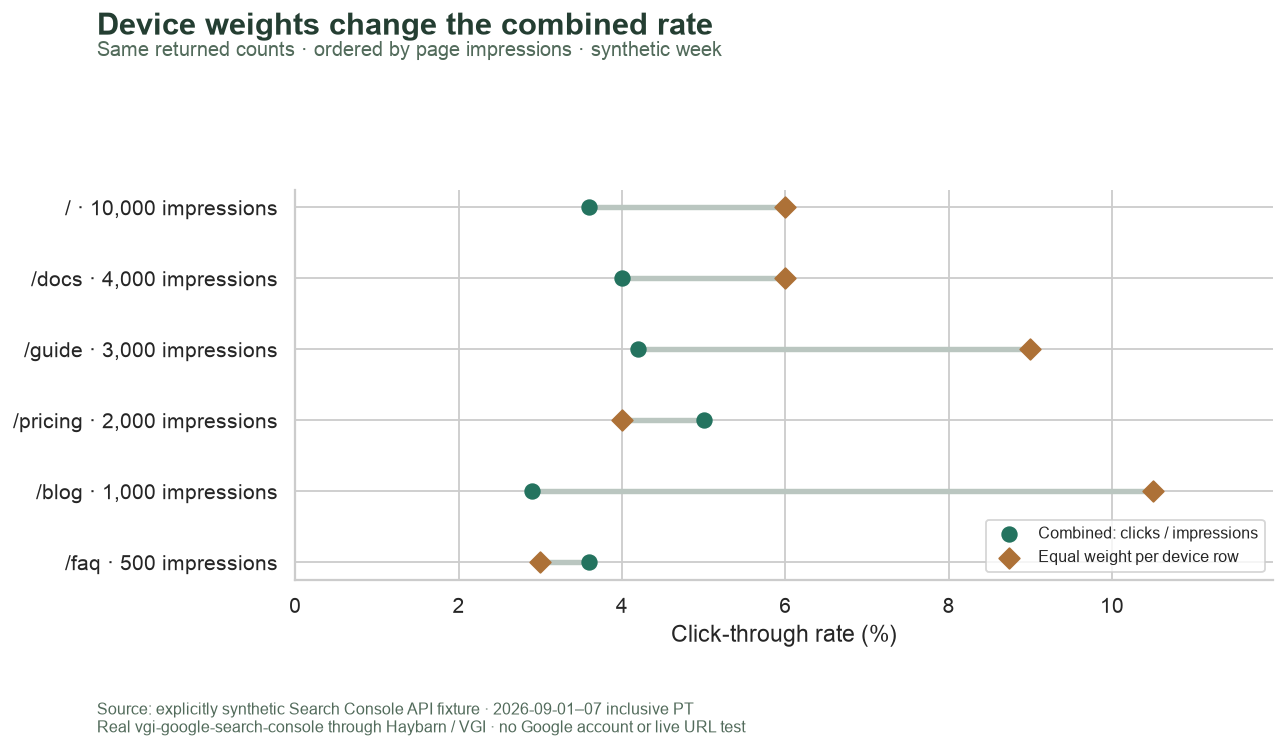

In [7]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))
y = np.arange(len(pages))
ax.hlines(y, pages.weighted_ctr_pct, pages.equal_device_ctr_pct, color="#bac6c0", lw=3)
ax.scatter(pages.weighted_ctr_pct, y, color="#24735f", s=65, label="Combined: clicks / impressions", zorder=3)
ax.scatter(
    pages.equal_device_ctr_pct, y, color="#ad7137", s=65, marker="D", label="Equal weight per device row", zorder=3
)
ax.set_yticks(y, [f"{r.page_path} · {r.impressions:,} impressions" for r in pages.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Click-through rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(pages.equal_device_ctr_pct.max(), pages.weighted_ctr_pct.max()) * 1.14)
ax.legend(loc="lower right", frameon=True, fontsize=9)
finish(
    fig,
    f"rates-min-{MIN_IMPRESSIONS}",
    "Device weights change the combined rate",
    "Same returned counts · ordered by page impressions · synthetic week",
)

In [8]:
largest = pages.iloc[pages.difference_pp.abs().argmax()]
display(
    Markdown(
        f"The largest absolute difference is on **{largest.page_path}**: "
        f"**{largest.weighted_ctr_pct:.2f}%** combined versus **{largest.equal_device_ctr_pct:.2f}%** "
        f"with equal device weights, a signed difference of **{largest.difference_pp:+.2f} percentage points**. "
        "This is a weighting effect within supplied rows, not evidence of a traffic change."
    )
)

The largest absolute difference is on **/blog**: **2.90%** combined versus **10.50%** with equal device weights, a signed difference of **+7.60 percentage points**. This is a weighting effect within supplied rows, not evidence of a traffic change.

## Inspect a bounded shortlist and retain the omissions

Eligibility uses the returned page-impression count. A deterministic three-page budget limits calls. The LATERAL request is materialized once; the subsequent left join retains every page, including those not inspected. A missing inspection is not a passing status. [URL inspection](https://developers.google.com/webmaster-tools/v1/urlInspection.index/inspect) describes the indexed version; it does not test a live URL or establish why past clicks occurred.

In [9]:
%%sql
CREATE TABLE shortlist AS
SELECT * FROM page_metrics WHERE impressions >= {{MIN_IMPRESSIONS}}
ORDER BY impressions DESC, page LIMIT 3;
CREATE TABLE inspections AS
SELECT s.site_url, s.page, i.site_url AS inspected_site, i.inspection_url AS inspected_url,
       i.verdict, i.coverage_state, i.last_crawl_time
FROM shortlist s,
LATERAL gsc.main.url_inspection(s.site_url, s.page, cache_ttl => 0) i;
CREATE TABLE review AS
SELECT p.*, i.verdict, i.coverage_state, i.last_crawl_time,
       CASE WHEN i.page IS NOT NULL THEN 'Inspected'
            WHEN p.impressions < {{MIN_IMPRESSIONS}} THEN 'Below threshold'
            ELSE 'Outside three-page budget' END AS review_state
FROM page_metrics p LEFT JOIN inspections i USING(site_url, page);

,Count


In [10]:
%%sql reviewed <<
SELECT replace(page, 'https://www.example.com', '') AS page_path,
       impressions, 100 * weighted_ctr AS ctr_pct, review_state, verdict, coverage_state, last_crawl_time
FROM review ORDER BY impressions DESC, page;

,page_path,impressions,ctr_pct,review_state,verdict,coverage_state,last_crawl_time
0,/,10000,3.6,Inspected,PASS,Submitted and indexed,2026-09-08 08:00:00-04:00
1,/docs,4000,4.0,Inspected,NEUTRAL,Alternate page with proper canonical tag,2026-09-08 08:00:00-04:00
2,/guide,3000,4.2,Inspected,FAIL,Excluded by noindex tag,2026-09-08 08:00:00-04:00
3,/pricing,2000,5.0,Outside three-page budget,None,None,NaT
4,/blog,1000,2.9,Outside three-page budget,None,None,NaT
5,/faq,500,3.6,Below threshold,None,None,NaT


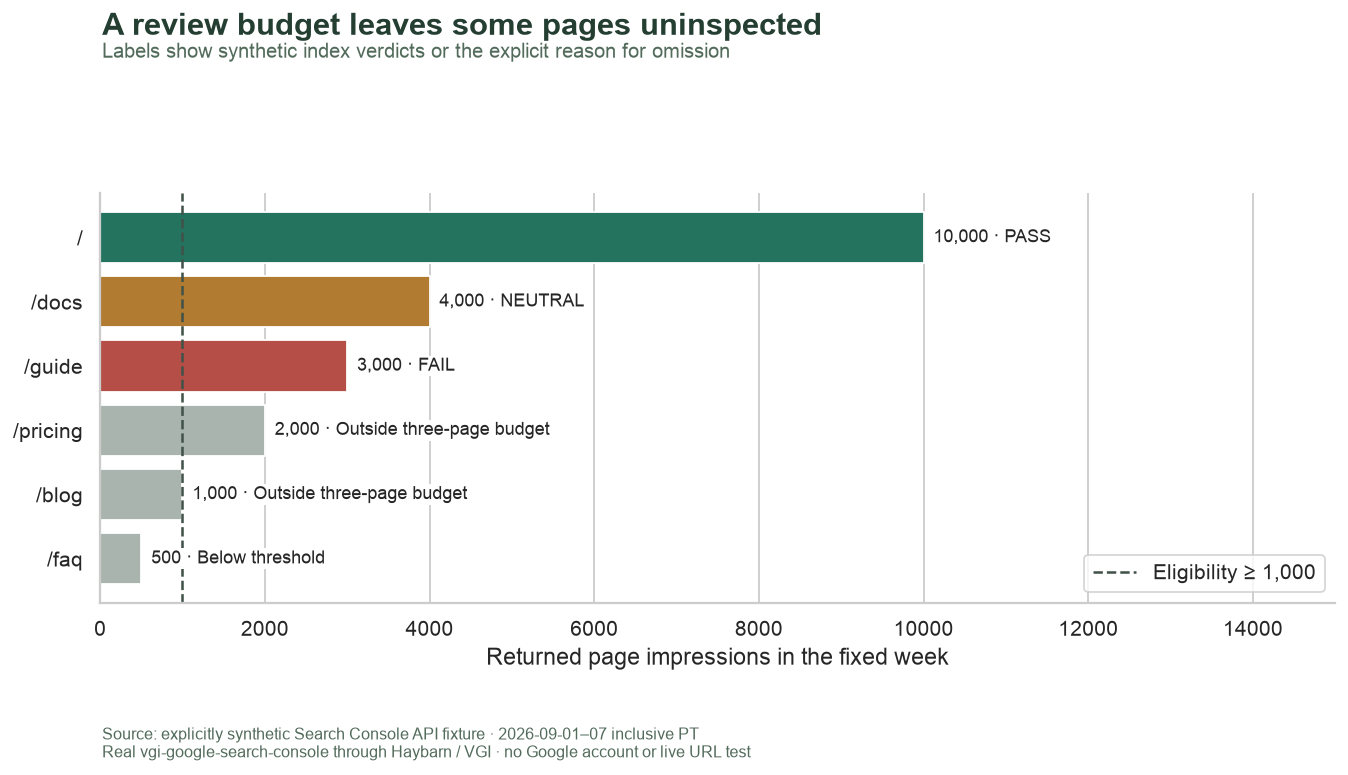

In [11]:
display(reviewed)
fig, ax = plt.subplots(figsize=(11, 6.0))
ax.grid(axis="y", visible=False)
palette = {"PASS": "#24735f", "NEUTRAL": "#b17c31", "FAIL": "#b54e46"}
y = np.arange(len(reviewed))
colors = [palette.get(v, "#aab4ae") for v in reviewed.verdict]
ax.barh(y, reviewed.impressions, color=colors)
ax.set_yticks(y, reviewed.page_path)
ax.invert_yaxis()
for i, row in enumerate(reviewed.itertuples()):
    label = row.verdict if pd.notna(row.verdict) else row.review_state
    ax.text(
        row.impressions + reviewed.impressions.max() * 0.012,
        i,
        f"{row.impressions:,} · {label}",
        va="center",
        fontsize=10,
        zorder=4,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.axvline(MIN_IMPRESSIONS, color="#415249", ls="--", lw=1.4, label=f"Eligibility ≥ {MIN_IMPRESSIONS:,}")
ax.set_xlim(0, max(reviewed.impressions.max() * 1.5, MIN_IMPRESSIONS * 1.08))
ax.set_xlabel("Returned page impressions in the fixed week")
ax.set_ylabel("")
ax.legend(loc="lower right", frameon=True)
finish(
    fig,
    f"review-min-{MIN_IMPRESSIONS}",
    "A review budget leaves some pages uninspected",
    "Labels show synthetic index verdicts or the explicit reason for omission",
)

## Check arithmetic, joins and the actual call budget

These checks distinguish zero clicks from missing metrics, preserve the page key through the row transform, and reconcile the two fixture aggregations. The local server log verifies that inspection calls were made exactly once per shortlisted URL. No assertion requires a particular status or CTR ranking.

In [12]:
%%sql checks <<
SELECT 'device keys unique' AS check_name,
       count(*) = count(DISTINCT (site_url, page, device)) AS passed FROM device_rows
UNION ALL SELECT 'metrics complete and bounded',
       count(*) > 0 AND count(*) FILTER (WHERE clicks IS NULL OR impressions IS NULL OR ctr IS NULL OR position IS NULL
          OR clicks < 0 OR impressions <= 0 OR clicks > impressions OR abs(ctr - clicks::DOUBLE / impressions) > 1e-12) = 0 FROM device_rows
UNION ALL SELECT 'page aggregation matches fixture API',
       count(*) = (SELECT count(*) FROM page_metrics) AND bool_and(p.clicks=a.clicks AND p.impressions=a.impressions
          AND abs(p.weighted_ctr-a.ctr)<1e-12 AND abs(p.weighted_position-a.position)<1e-12)
       FROM page_metrics p JOIN api_pages a USING(site_url,page)
UNION ALL SELECT 'shortlist obeys threshold and budget',
       count(*) <= 3 AND count(*) FILTER (WHERE impressions < {{MIN_IMPRESSIONS}}) = 0 FROM shortlist
UNION ALL SELECT 'inspection retains parent identity',
       count(*) = (SELECT count(*) FROM shortlist) AND coalesce(bool_and(site_url=inspected_site AND page=inspected_url),true) FROM inspections
UNION ALL SELECT 'review retains every page once',
       count(*)=(SELECT count(*) FROM page_metrics) AND count(*)=count(DISTINCT(site_url,page)) FROM review
UNION ALL SELECT 'uninspected pages remain missing',
       count(*) FILTER (WHERE review_state <> 'Inspected' AND (verdict IS NOT NULL OR last_crawl_time IS NOT NULL))=0 FROM review;

In [13]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
calls = [r for r in fixture.requests if r["path"] == "/v1/urlInspection/index:inspect"]
selected_count = int((reviewed.review_state == "Inspected").sum())
assert len(calls) == selected_count
assert len({r["body"]["inspectionUrl"] for r in calls}) == selected_count
page_calls = [r for r in fixture.requests if r["path"].endswith("/searchAnalytics/query")]
assert any(r["body"].get("startRow", 0) > 0 for r in page_calls)
display(
    Markdown(
        f"At the **{MIN_IMPRESSIONS:,}-impression** threshold, eligible pages: "
        f"**{int((reviewed.impressions >= MIN_IMPRESSIONS).sum())} of {len(reviewed)}**. "
        f"Completed inspections: **{selected_count}**. "
        f"Inspection requests recorded by the local server: **{len(calls)}**, with no repeated URL. "
        f"All **{len(checks) + 3} accounting, provenance and request checks** pass. "
        "The fixture statuses are separate from the traffic window and cannot explain its CTR."
    )
)

,check_name,passed
0,device keys unique,True
1,metrics complete and bounded,True
2,page aggregation matches fixture API,True
3,shortlist obeys threshold and budget,True
4,inspection retains parent identity,True
5,review retains every page once,True
6,uninspected pages remain missing,True


At the **1,000-impression** threshold, eligible pages: **5 of 6**. Completed inspections: **3**. Inspection requests recorded by the local server: **3**, with no repeated URL. All **10 accounting, provenance and request checks** pass. The fixture statuses are separate from the traffic window and cannot explain its CTR.

## Try one change

Change `MIN_IMPRESSIONS` from **1000** to **5000**, restart and run all. Predict how many pages remain eligible and inspect the review table and second chart. The first chart and all traffic metrics should remain unchanged; the inspection count can fall below the three-page budget. No conclusion follows about uninspected URLs. Restore **1000** for the saved default.

This notebook deliberately has no live mode: the fixture demonstrates mechanics without requiring a property or credentials. For your own data, follow the repository authentication documentation, choose a property and date window you are authorized to read, and reassess API truncation and aggregation semantics before applying the calculations.

In [14]:
assert connection.execute("SELECT count(*) FROM duckdb_secrets() WHERE persistent").fetchall() == [(0,)]
connection.close()
fixture.close()
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>